# NexuStock · Entrenamiento y evaluación del modelo de demanda

| | |
|---|---|
| **Proyecto** | NexuStock: gestión y predicción de inventario para una carnicería independiente |
| **Entregable** | Informe de evaluación del modelo · Kanban v3, tarea 26 |
| **Responsable** | Manuel Bustamante (Data Scientist) |
| **Entrada** | `data/processed/semanal.csv` (notebook 02) |
| **Salidas** | `models/demanda_rf_v1.0.0.joblib`, `models/registro_modelos_ml.sql`, `data/processed/predicciones_prueba_2024.csv` |

## Objetivo

Entrenar y comparar los algoritmos definidos en el ERS para proyectar la demanda semanal en kg por producto, y seleccionar el modelo que se integrará al backend mediante `predict.py`.

## Diseño experimental

| Elemento | Definición |
|---|---|
| Problema | Regresión supervisada: predecir `kg` por producto y semana |
| Entrenamiento | 2022-2023 (96 semanas) |
| Prueba | 2024 (52 semanas), usado una sola vez |
| Métrica | MAE en kg: general, en ventanas festivas y en semanas normales |
| Línea base | Promedio de las últimas 8 semanas, igual al respaldo del backend (CU-11) |
| Modelos | Regresión lineal, Ridge y Random Forest |
| Criterio de aceptación | Superar a la línea base en MAE general y en festivos (ERS) |

Todo ajuste de parámetros usa solo el periodo de entrenamiento. La prueba en 2024 replica el uso en la plataforma: para cada semana, el modelo conoce las ventas reales de las semanas anteriores y predice la siguiente.

## 1. Configuración del entorno

El valor fijo de `random_state` hace que Random Forest produzca los mismos resultados en cada ejecución.

In [1]:
from pathlib import Path
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option('display.float_format', '{:,.2f}'.format)
sns.set_theme(style='whitegrid')

BASE = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
PROCESSED = BASE / 'data' / 'processed'
MODELS = BASE / 'models'
MODELS.mkdir(exist_ok=True)
RANDOM_STATE = 42
print('scikit-learn', sklearn.__version__)


scikit-learn 1.9.1


## 2. Datos, variables y separación

Quedan fuera de las variables `producto_id` (el nivel de cada producto lo aportan los lags), `dias_quiebre` (información futura) y `es_festiva` (solo se usa para segmentar la evaluación). Las filas se ordenan por semana para la validación cruzada temporal de la sección 6.

In [2]:
df = pd.read_csv(PROCESSED / 'semanal.csv', parse_dates=['semana'])
df = df.sort_values(['semana', 'producto_id']).reset_index(drop=True)

CATEGORICAS = ['categoria']
NUMERICAS = ['lag_1', 'lag_2', 'lag_3', 'lag_4', 'media_4', 'media_8',
             'dias_hasta_18', 'fiestas_patrias', 'semana_santa', 'cuaresma', 'feriado_largo',
             'evento_especial', 'quincena', 'fin_mes', 'dias_cerrado',
             'semana_anio', 'mes', 't', 'dias_quiebre_lag_1']
VARIABLES = CATEGORICAS + NUMERICAS
OBJETIVO = 'kg'

ent = df[df['conjunto'] == 'entrenamiento']
prueba = df[df['conjunto'] == 'prueba']
X_ent, y_ent = ent[VARIABLES], ent[OBJETIVO]
X_prueba, y_prueba = prueba[VARIABLES], prueba[OBJETIVO]
festiva = prueba['es_festiva'] == 1

print('Entrenamiento:', X_ent.shape, ent['semana'].min().date(), '->', ent['semana'].max().date())
print('Prueba:       ', X_prueba.shape, prueba['semana'].min().date(), '->', prueba['semana'].max().date())
print('Filas festivas en prueba:', festiva.sum())


Entrenamiento: (2304, 20) 2022-02-28 -> 2023-12-25
Prueba:        (1248, 20) 2024-01-01 -> 2024-12-23
Filas festivas en prueba: 120


## 3. Función de evaluación

Todos los modelos se evalúan con la misma función sobre el mismo conjunto de prueba.

- **MAE:** error absoluto medio de la predicción semanal de un producto, en kg.
- **`error_%`:** MAE dividido por la venta media semanal por producto, como medida relativa.

In [3]:
def evaluar(nombre, pred):
    pred = np.asarray(pred)
    return {
        'modelo': nombre,
        'mae_general': mean_absolute_error(y_prueba, pred),
        'mae_festivos': mean_absolute_error(y_prueba[festiva], pred[festiva.values]),
        'mae_normales': mean_absolute_error(y_prueba[~festiva], pred[~festiva.values]),
        'error_%': mean_absolute_error(y_prueba, pred) / y_prueba.mean() * 100,
    }

resultados = []
print('kg promedio por semana-producto en 2024:', round(y_prueba.mean(), 2))


kg promedio por semana-producto en 2024: 33.65


## 4. Línea base: promedio de 8 semanas

Predice para cada semana el promedio de las 8 anteriores. Es el cálculo que ya usa el backend cuando el modelo no está disponible; el modelo solo aporta valor si mejora este resultado.

In [4]:
pred_base = prueba['media_8']
resultados.append(evaluar('Línea base (promedio 8 semanas)', pred_base))
pd.DataFrame(resultados).round(2)


,modelo,mae_general,mae_festivos,mae_normales,error_%
0,Línea base (promedio 8 semanas),5.64,9.80,5.20,16.77


**Resultado.** MAE general de 5,64 kg (16,8 % de la venta media) y de 9,80 kg en festivos. El error en festivos casi duplica al de las semanas normales (5,20 kg), porque un promedio histórico no puede anticipar un evento.

## 5. Regresión lineal y Ridge

El preprocesamiento (codificación one-hot de la categoría y estandarización de las variables numéricas) forma parte del `Pipeline`. Así se ajusta solo con los datos de entrenamiento y `predict.py` puede recibir las columnas sin transformar. Ridge agrega una penalización L2 sobre los coeficientes.

In [5]:
prepro_lineal = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), CATEGORICAS),
    ('num', StandardScaler(), NUMERICAS),
])

lineal = Pipeline([('prepro', prepro_lineal), ('modelo', LinearRegression())])
lineal.fit(X_ent, y_ent)
resultados.append(evaluar('Regresión lineal', lineal.predict(X_prueba)))

ridge = Pipeline([('prepro', prepro_lineal), ('modelo', Ridge(alpha=10))])
ridge.fit(X_ent, y_ent)
resultados.append(evaluar('Ridge (alpha=10)', ridge.predict(X_prueba)))
display(pd.DataFrame(resultados).round(2))

coef = pd.Series(lineal.named_steps['modelo'].coef_,
                 index=lineal.named_steps['prepro'].get_feature_names_out())
coef.sort_values(key=abs, ascending=False).head(8).round(2)


,modelo,mae_general,mae_festivos,mae_normales,error_%
0,Línea base (promedio 8 semanas),5.64,9.80,5.20,16.77
1,Regresión lineal,5.43,8.85,5.07,16.14
2,Ridge (alpha=10),5.42,8.84,5.06,16.12


num__media_8           12.89
num__semana_anio       -7.19
num__mes                7.15
num__lag_1              2.29
cat__categoria_Pollo    2.25
num__dias_cerrado      -2.09
num__lag_3              1.91
num__fin_mes            1.69
dtype: float64

**Resultado.** La regresión lineal obtiene un MAE general de 5,43 kg y Ridge de 5,42 kg; en festivos, 8,85 y 8,84 kg. Ambos mejoran a la línea base en 4 % en general y en 10 % en festivos.

Los coeficientes de `semana_anio` (−7,19) y `mes` (7,15) tienen magnitud similar y signo opuesto. Es un caso de multicolinealidad: ambas variables representan la posición en el año y sus efectos se compensan, por lo que no son interpretables por separado. La penalización de Ridge estabiliza los coeficientes sin cambiar el error.

## 6. Random Forest con búsqueda de hiperparámetros

Los hiperparámetros se seleccionan con `GridSearchCV` y `TimeSeriesSplit` (4 particiones): cada partición entrena con el pasado y valida con el periodo siguiente, dentro de 2022-2023. El conjunto de prueba no interviene en la selección.

| Hiperparámetro | Valores | Efecto |
|---|---|---|
| `max_depth` | None, 12 | Profundidad máxima de cada árbol |
| `min_samples_leaf` | 1, 3, 5 | Filas mínimas por hoja; valores altos reducen el sobreajuste |
| `max_features` | 1,0; 0,5 | Fracción de variables evaluadas en cada corte |

In [6]:
prepro_arbol = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), CATEGORICAS),
    ('num', 'passthrough', NUMERICAS),
])
rf = Pipeline([('prepro', prepro_arbol),
               ('modelo', RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1))])

grilla = {
    'modelo__max_depth': [None, 12],
    'modelo__min_samples_leaf': [1, 3, 5],
    'modelo__max_features': [1.0, 0.5],
}
busqueda = GridSearchCV(rf, grilla, cv=TimeSeriesSplit(n_splits=4),
                        scoring='neg_mean_absolute_error', n_jobs=-1)
inicio = time.perf_counter()
busqueda.fit(X_ent, y_ent)
print(f'Búsqueda: {time.perf_counter() - inicio:.0f} s')
print('Mejores parámetros:', busqueda.best_params_)
print('MAE validación cruzada (solo 2022-2023):', round(-busqueda.best_score_, 2))

cv = pd.DataFrame(busqueda.cv_results_)[['params', 'mean_test_score']]
cv['mae_cv'] = -cv['mean_test_score']
cv.sort_values('mae_cv')[['params', 'mae_cv']].head(5)


Búsqueda: 20 s
Mejores parámetros: {'modelo__max_depth': 12, 'modelo__max_features': 0.5, 'modelo__min_samples_leaf': 5}
MAE validación cruzada (solo 2022-2023): 6.2


,params,mae_cv
11,"{'modelo__max_depth': 12, 'modelo__max_feature...",6.20
5,"{'modelo__max_depth': None, 'modelo__max_featu...",6.21
10,"{'modelo__max_depth': 12, 'modelo__max_feature...",6.22
4,"{'modelo__max_depth': None, 'modelo__max_featu...",6.23
9,"{'modelo__max_depth': 12, 'modelo__max_feature...",6.35


**Resultado.** La mejor combinación es `max_depth=12`, `min_samples_leaf=5` y `max_features=0.5`, con un MAE de validación cruzada de 6,20 kg. Este valor es mayor que el de prueba porque las primeras particiones entrenan con pocos meses de historia. Las cinco mejores combinaciones quedan entre 6,20 y 6,35 kg: el resultado no depende de un ajuste fino.

## 7. Comparación de modelos

In [7]:
rf_final = busqueda.best_estimator_
pred_rf = rf_final.predict(X_prueba)
resultados.append(evaluar('Random Forest', pred_rf))

tabla = pd.DataFrame(resultados).set_index('modelo')
tabla['mejora_vs_base_%'] = (1 - tabla['mae_general'] / tabla.loc['Línea base (promedio 8 semanas)', 'mae_general']) * 100
tabla.round(2)


,mae_general,mae_festivos,mae_normales,error_%,mejora_vs_base_%
modelo,,,,,
Línea base (promedio 8 semanas),5.64,9.80,5.20,16.77,0.00
Regresión lineal,5.43,8.85,5.07,16.14,3.72
Ridge (alpha=10),5.42,8.84,5.06,16.12,3.87
Random Forest,5.14,8.83,4.75,15.29,8.83


**Resultado.**

| Modelo | MAE general | MAE festivos | MAE normales | Error % |
|---|---|---|---|---|
| Línea base (8 semanas) | 5,64 | 9,80 | 5,20 | 16,8 % |
| Regresión lineal | 5,43 | 8,85 | 5,07 | 16,1 % |
| Ridge | 5,42 | 8,84 | 5,06 | 16,1 % |
| **Random Forest** | **5,14** | **8,83** | **4,75** | **15,3 %** |

Random Forest obtiene el menor error en las tres mediciones y reduce el MAE general en 9 % respecto de la línea base. En festivos, los tres modelos quedan en un rango estrecho (8,83 a 8,85 kg) y todos mejoran a la línea base en cerca de 10 %. El criterio de aceptación del ERS se cumple.

El error en festivos sigue siendo alto por dos razones: el entrenamiento contiene solo dos ocurrencias de Fiestas Patrias y de Semana Santa, y en 2024 esas semanas tuvieron quiebres que redujeron la venta observada.

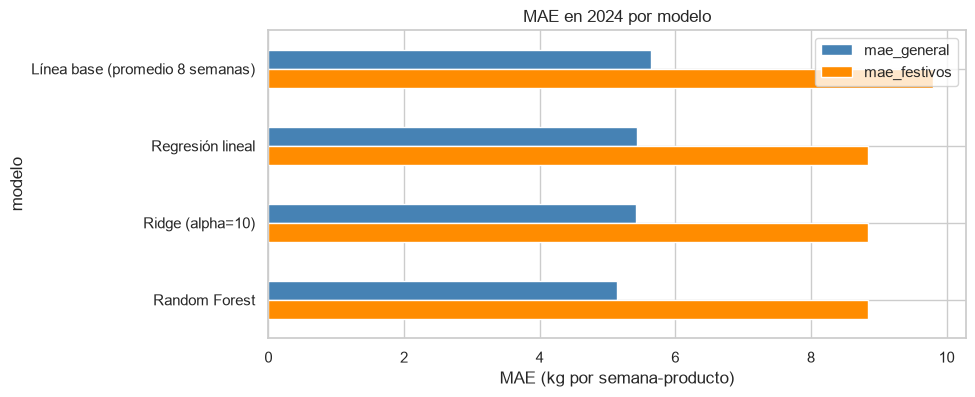

In [8]:
ax = tabla[['mae_general', 'mae_festivos']].plot.barh(figsize=(9, 4), color=['steelblue', 'darkorange'])
ax.set_xlabel('MAE (kg por semana-producto)')
ax.set_title('MAE en 2024 por modelo')
ax.invert_yaxis()
plt.show()


## 8. Importancia de las variables

Reducción media del error que aporta cada variable en los cortes de los árboles.

In [9]:
importancia = pd.Series(rf_final.named_steps['modelo'].feature_importances_,
                        index=rf_final.named_steps['prepro'].get_feature_names_out())
importancia.sort_values(ascending=False).head(10).round(3)


num__media_8           0.43
num__media_4           0.30
num__lag_3             0.08
num__lag_1             0.07
num__lag_4             0.04
num__lag_2             0.03
num__dias_hasta_18     0.02
num__semana_anio       0.01
cat__categoria_Pollo   0.01
num__t                 0.00
dtype: float64

**Resultado.** Las medias móviles concentran el 73 % de la importancia (`media_8` 0,43; `media_4` 0,30), seguidas de los lags individuales. El historial reciente determina el nivel de la predicción, y las variables de calendario corrigen las semanas especiales. Su importancia agregada es baja porque afectan a pocas semanas, pero son las responsables de la reducción del error en festivos.

## 9. Análisis de errores

Error por categoría y según si la semana tuvo días con quiebre de stock.

In [10]:
analisis = prueba[['producto_id', 'categoria', 'semana', 'kg', 'dias_quiebre', 'es_festiva']].copy()
analisis['pred_rf'] = pred_rf
analisis['pred_base'] = pred_base.values
analisis['error_rf'] = (analisis['kg'] - analisis['pred_rf']).abs()
analisis['error_base'] = (analisis['kg'] - analisis['pred_base']).abs()

display(analisis.groupby('categoria')[['kg', 'error_base', 'error_rf']].mean().round(2))
analisis.groupby(analisis['dias_quiebre'] > 0)[['error_base', 'error_rf']].mean().round(2)


,kg,error_base,error_rf
categoria,,,
Cerdo,29.85,5.05,4.71
Embutidos,27.30,4.60,3.90
Pescados,14.71,3.14,2.67
Pollo,68.30,10.51,10.01
Vacuno,30.47,5.20,4.69


,error_base,error_rf
dias_quiebre,,
False,5.28,4.77
True,6.98,6.49


**Resultado.** Random Forest reduce el error frente a la línea base en las cinco categorías. Pollo presenta el mayor error absoluto (10,01 kg) porque su volumen medio (68,30 kg) más que duplica al de las demás categorías; en términos relativos es comparable.

En las semanas con quiebre el error aumenta 36 % (6,49 kg frente a 4,77 kg), porque la venta observada está censurada por la falta de stock: el modelo estima la demanda y la venta real queda por debajo de ella. Por la misma razón, la mejora frente a la línea base es menor en esas semanas (7 %) que en las semanas sin quiebre (10 %).

## 10. Comparación de la serie real y la predicha en 2024

Prietas (P020, Embutidos) y Alitas de Pollo (P013, el producto con más días de quiebre). Esta comparación es la que verá el administrador en el dashboard.

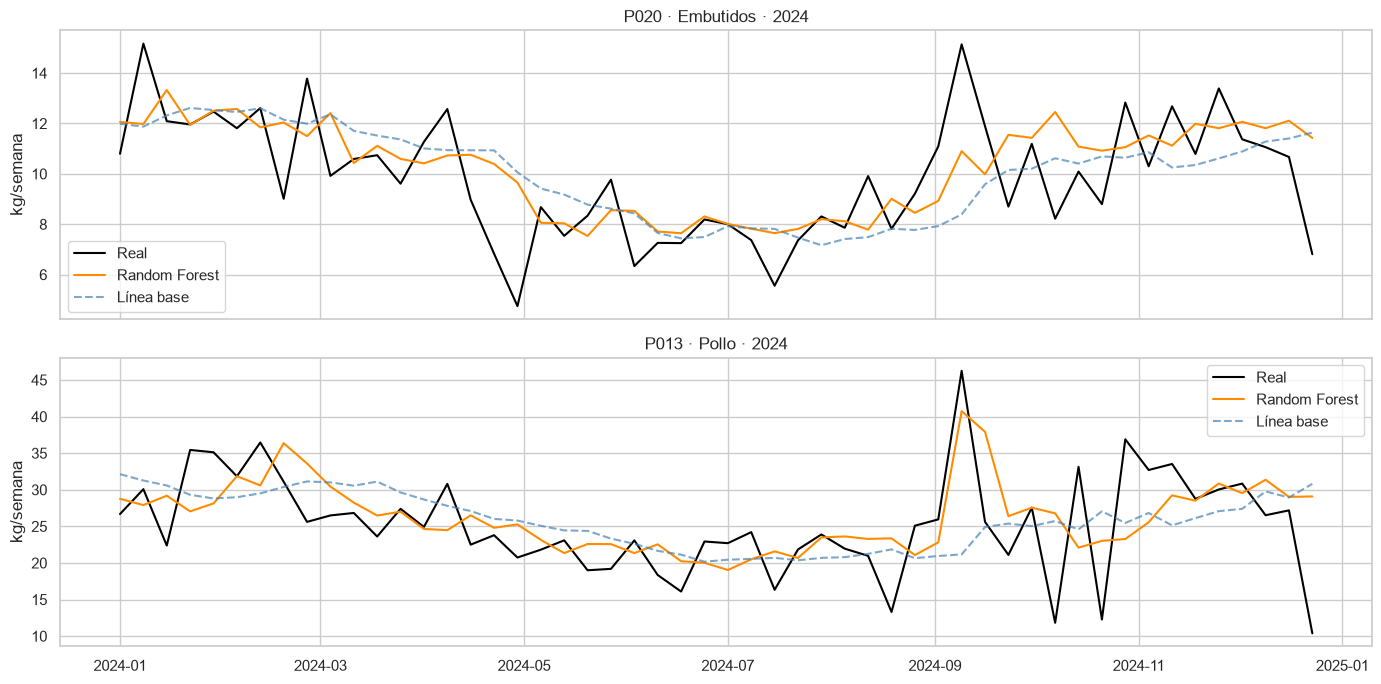

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for ax, prod in zip(axes, ['P020', 'P013']):
    a = analisis[analisis['producto_id'] == prod]
    ax.plot(a['semana'], a['kg'], label='Real', color='black')
    ax.plot(a['semana'], a['pred_rf'], label='Random Forest', color='darkorange')
    ax.plot(a['semana'], a['pred_base'], label='Línea base', color='steelblue', ls='--', alpha=0.7)
    ax.set_title(f'{prod} · {a["categoria"].iloc[0]} · 2024')
    ax.set_ylabel('kg/semana')
    ax.legend()
plt.tight_layout()
plt.show()


## 11. Acotamiento de las predicciones

El ERS exige proyecciones positivas y acotadas a la capacidad del local. El tope se fija en 1,5 veces la máxima venta semanal de cada producto en el periodo de entrenamiento y se guarda junto al modelo para que `predict.py` lo aplique.

In [12]:
topes = (ent.groupby('producto_id')['kg'].max() * 1.5).round(2)
pred_acotada = np.clip(pred_rf, 0, prueba['producto_id'].map(topes).values)
print('Predicciones negativas:', (pred_rf < 0).sum(),
      '| sobre el tope:', (pred_rf > prueba['producto_id'].map(topes).values).sum())
print('MAE con acotamiento:', round(mean_absolute_error(y_prueba, pred_acotada), 3))


Predicciones negativas: 0 | sobre el tope: 0
MAE con acotamiento: 5.144


**Resultado.** No hay predicciones negativas ni sobre el tope; el MAE no cambia (5,144 kg). Random Forest promedia valores observados, por lo que no genera negativos. El acotamiento se mantiene como protección ante datos de entrada anómalos en producción.

## 12. Latencia de predicción

Con una sola fila, el procesamiento paralelo agrega más costo del que ahorra, por lo que la predicción se configura con `n_jobs=1`.

In [13]:
rf_final.set_params(modelo__n_jobs=1)
X_una = X_prueba.iloc[[0]]
inicio = time.perf_counter()
for _ in range(20):
    rf_final.predict(X_una)
print(f'Latencia por predicción: {(time.perf_counter() - inicio) / 20 * 1000:.1f} ms')


Latencia por predicción: 37.2 ms


**Resultado.** Cada predicción toma cerca de 35 ms, muy por debajo del límite de 2,0 s del ERS (RNF).

> **Pendiente para `predict.py`.** En una invocación como proceso hijo, el tiempo total incluye la importación de pandas y scikit-learn. En el entorno local (entorno virtual dentro de OneDrive) la importación tarda cerca de 3,3 s, mientras que la carga del modelo y la predicción suman 0,2 s. Debe medirse en la imagen Docker y, si es necesario, predecir todos los productos en una sola invocación.

## 13. Serialización del modelo

El artefacto guarda, además del `Pipeline`, la lista ordenada de variables, los topes por producto, las métricas, las ventanas de entrenamiento y prueba, y la versión de scikit-learn, para detectar incompatibilidades al cargarlo en la imagen del backend. El modelo no se reentrena con 2024, porque ese periodo es el que se usa en la demostración del dashboard.

In [14]:
VERSION = '1.0.0'
fila = tabla.loc['Random Forest']
artefacto = {
    'modelo': rf_final,
    'variables': VARIABLES,
    'topes_kg': topes.to_dict(),
    'algoritmo': 'RandomForestRegressor',
    'version': VERSION,
    'mae_general': round(float(fila['mae_general']), 3),
    'mae_festivos': round(float(fila['mae_festivos']), 3),
    'entrenado_desde': str(ent['semana'].min().date()),
    'entrenado_hasta': '2023-12-31',
    'prueba_desde': str(prueba['semana'].min().date()),
    'prueba_hasta': '2024-12-29',
    'parametros': busqueda.best_params_,
    'sklearn_version': sklearn.__version__,
}
ruta = MODELS / f'demanda_rf_v{VERSION}.joblib'
joblib.dump(artefacto, ruta, compress=3)
print('Guardado:', ruta, f'({ruta.stat().st_size / 1e6:.1f} MB)')

cargado = joblib.load(ruta)
assert np.allclose(cargado['modelo'].predict(X_prueba), pred_rf)
print('El artefacto cargado predice lo mismo que el modelo en memoria')


Guardado: c:\Users\manu_\OneDrive\Escritorio\NexuStock\NexuStock\Codigo\ml-engine\models\demanda_rf_v1.0.0.joblib (2.8 MB)
El artefacto cargado predice lo mismo que el modelo en memoria


## 14. Registro en `MODELOS_ML`

Sentencia de inserción con las columnas de la tabla definida en `init.sql`. Se guarda en `models/registro_modelos_ml.sql` para cargarla en la base de datos.

In [15]:
a = artefacto
sql = f"""INSERT INTO MODELOS_ML (algoritmo, version, mae_general, mae_festivos,
                        entrenado_desde, entrenado_hasta, prueba_desde, prueba_hasta,
                        artefacto_ruta, activo)
VALUES ('{a['algoritmo']}', '{a['version']}', {a['mae_general']}, {a['mae_festivos']},
        '{a['entrenado_desde']}', '{a['entrenado_hasta']}', '{a['prueba_desde']}', '{a['prueba_hasta']}',
        'ml-engine/models/{ruta.name}', TRUE);"""
print(sql)
(MODELS / 'registro_modelos_ml.sql').write_text(sql + '\n', encoding='utf-8')

INSERT INTO MODELOS_ML (algoritmo, version, mae_general, mae_festivos,
                        entrenado_desde, entrenado_hasta, prueba_desde, prueba_hasta,
                        artefacto_ruta, activo)
VALUES ('RandomForestRegressor', '1.0.0', 5.144, 8.835,
        '2022-02-28', '2023-12-31', '2024-01-01', '2024-12-29',
        'ml-engine/models/demanda_rf_v1.0.0.joblib', TRUE);


385

## 15. Exportación de las predicciones de prueba

Predicciones de 2024 por producto y semana. Sirven como evidencia del informe y como referencia para verificar los valores que muestre el dashboard.

In [16]:
analisis.to_csv(PROCESSED / 'predicciones_prueba_2024.csv', index=False)
print('Guardado:', PROCESSED / 'predicciones_prueba_2024.csv', analisis.shape)

Guardado: c:\Users\manu_\OneDrive\Escritorio\NexuStock\NexuStock\Codigo\ml-engine\data\processed\predicciones_prueba_2024.csv (1248, 10)


## Conclusiones

1. Random Forest es el modelo seleccionado: MAE de 5,14 kg por producto y semana (15,3 % de la venta media), 9 % menor que el de la línea base.
2. Todos los modelos superan a la línea base en festivos (8,83 a 8,85 kg frente a 9,80 kg), lo que cumple el criterio del ERS.
3. El historial reciente explica la mayor parte de la demanda; las variables de calendario corrigen las semanas de eventos.
4. Parte del error en festivos y en semanas con quiebre se debe a la censura de la venta, no a la predicción.

| Pendiente | Responsable |
|---|---|
| Implementar `predict.py` según el contrato de CU-08 y medir la latencia en la imagen Docker | Manuel |
| Definir cómo llega el `.joblib` a la imagen, ya que `.gitignore` excluye `*.joblib` (H-08) | Manuel |
| Imagen del backend con Python 3.12 y la misma versión de scikit-learn (H-06) | Ambos |
| Cargar `registro_modelos_ml.sql` en la base | Ignacio |